# Numerical experiments: reproducing the paper's figures

This notebook runs the sliding-bar simulation used throughout the paper
and reproduces its seven computed figures, using the modules in this
directory (`inductance.py`, `dynamics.py`, `models.py`, `figures.py`). The paper's
two schematic diagrams -- the circuit itself, and the field of a current
element -- are hand drawn rather than computed, so they have no cell here.

**Runtime.** Every cell below runs at a `FULL_RESOLUTION = False` default
that finishes the whole notebook in well under two minutes on an ordinary
laptop, with or without `numba` installed. Setting `FULL_RESOLUTION = True`
in the next cell switches every figure to the paper's exact parameters and
step counts; that reproduction is fast (well under a minute, dominated by
the grid scan) if `numba` is installed (`pip install numba`, no compiler
needed), but the closed-form self-inductance evaluation is called millions
of times per figure, so **without numba the full-resolution grid scan
alone can take on the order of a day** -- see `_jit.py` and
`requirements.txt`. The reduced default does not switch off `numba`; it
only lowers the step counts and grid size so the notebook is fast either
way.

In [1]:
import sys, time
sys.path.insert(0, '.')

import numpy as np
import matplotlib.pyplot as plt

import _jit
import inductance, dynamics, models, figures

print("numba available:", _jit.HAVE_NUMBA,
      "-- simulations will run" if _jit.HAVE_NUMBA else "-- WARNING: numba not found, simulations will run",
      "~150x slower without it (still correct, just slow); see requirements.txt.")


numba available: True -- simulations will run ~150x slower without it (still correct, just slow); see requirements.txt.


## Configuration

Set `FULL_RESOLUTION = True` to reproduce the paper's figures exactly
(paper step counts and $17\times17$ grid); leave it `False` for a fast
demo run. Physical parameters below (`l`, `x0`, `p0`, `mu`, `dt`) match
the paper's Section "Results" defaults in every case; only the number of
integration steps and the grid resolution of the last figure change with
this flag.

In [2]:
FULL_RESOLUTION = False  # set True to reproduce the paper's figures exactly

# Paper defaults, Section "Results": mu0=1, l=100, x0=500, p0=-1e-2, dt=2e-4
l, x0, p0, mu, dt, rho = 100.0, 500.0, -1.e-2, 1.0, 2.e-4, 1.0

N_NORMAL = 4_000_000 if FULL_RESOLUTION else 200_000   # over-damped trajectory figure
N_LARGE  = 1_000_000 if FULL_RESOLUTION else 200_000    # under-damped, energy, force-fit
N_PRINT_NORMAL = 400 if FULL_RESOLUTION else 200
N_PRINT_LARGE  = 20

print(f"FULL_RESOLUTION={FULL_RESOLUTION}: N_NORMAL={N_NORMAL:,}  N_LARGE={N_LARGE:,}")


FULL_RESOLUTION=False: N_NORMAL=200,000  N_LARGE=200,000


## Figure: $x$, $p_x$, $I$ vs $t$ -- over-damped case ($B_0=2\times10^{-2}$)

Paper (Section "Results"): with $\rho=1$ (copper) and $B_0=2\times10^{-2}$
($\approx1$T), the standard no-self-inductance solution (dashed) agrees
well with the full simulation, and the bar stops after moving about
1 mm at a peak speed of about 13 cm/s. Reproduces the paper's over-damped trajectory figure.

**Reduced-resolution note**: this field is very weak, so the bar takes about 667 reduced time units to fully stop; the `FULL_RESOLUTION=False` default (200,000 steps = 40 time units) shows only the start of that decay, not the full stop. Set `FULL_RESOLUTION = True` above to see the complete trajectory.

ran 200,000 steps in 0.29s, 1000 points recorded


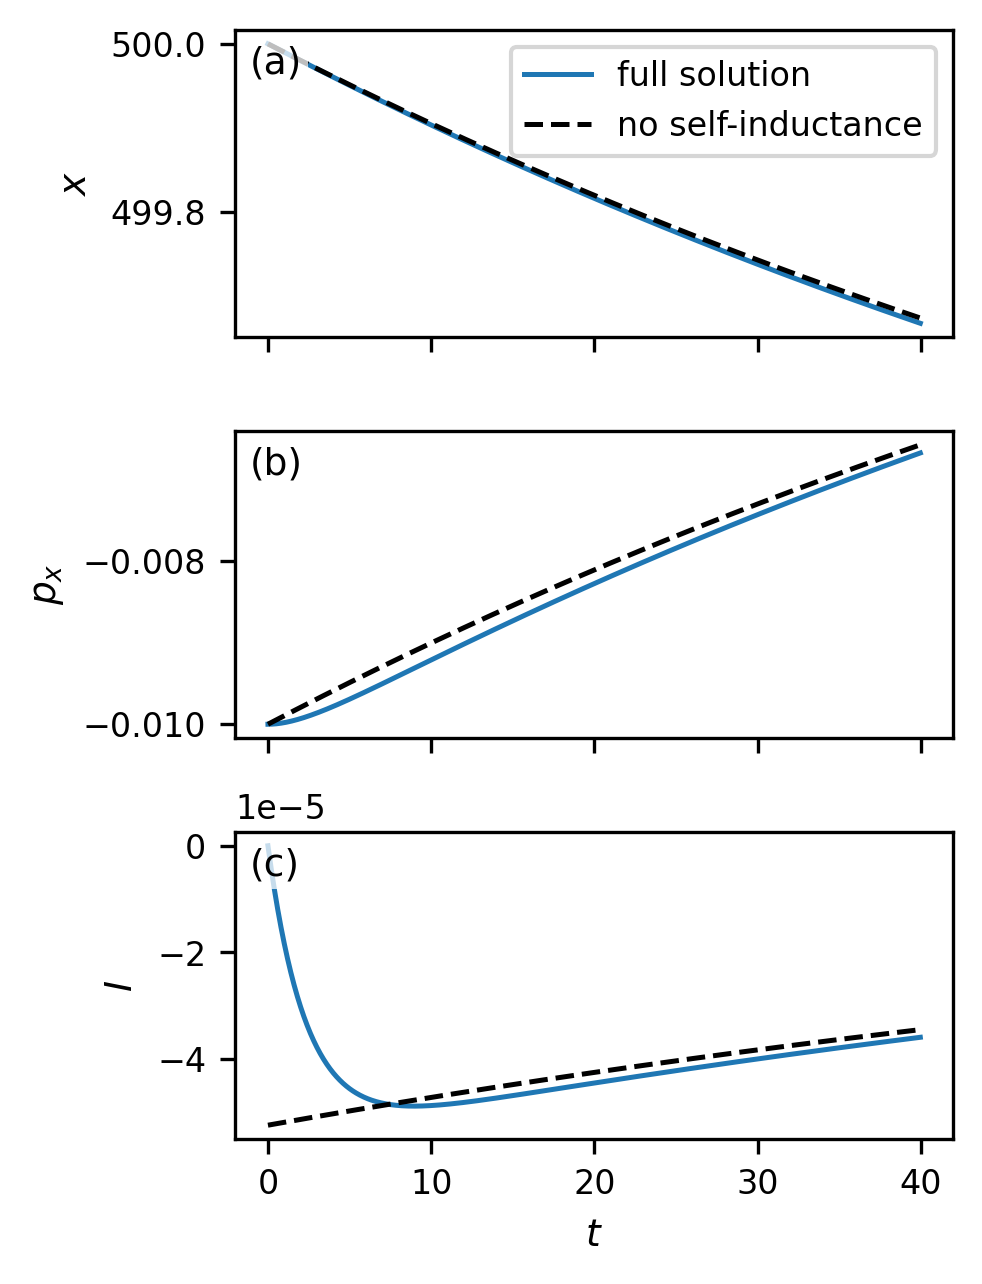

peak speed |p| = 0.010000  (reduced units)
total distance moved = 0.332783  (reduced units, d=1)


In [3]:
t0 = time.time()
B_normal = 2.e-2
x_n, p_n, I_n, F_n, K_n, Eb_n, Q_n = dynamics.verlet_integrate(
    x0, p0, l, B_normal, rho, dt, N_NORMAL, N_PRINT_NORMAL)
x_n, p_n, I_n = np.array(x_n), np.array(p_n), np.array(I_n)
t_n = N_PRINT_NORMAL * dt * np.arange(len(x_n))
print(f"ran {N_NORMAL:,} steps in {time.time()-t0:.2f}s, {len(x_n)} points recorded")

x_model_n = models.x_pos0(t_n, x0, p0, B_normal, rho, l)
p_model_n = models.p_pos0(t_n, p0, B_normal, rho, l, x0)
I_model_n = models.I_pos0(t_n, p0, B_normal, rho, l, x0)

fig = figures.plot_xpI(t_n, x_n, p_n, I_n, x_model_n, p_model_n, I_model_n)
plt.show()

print(f"peak speed |p| = {np.max(np.abs(p_n)):.6f}  (reduced units)")
print(f"total distance moved = {x0 - x_n.min():.6f}  (reduced units, d=1)")


## Figure: $x$, $p_x$, $I$ vs $t$ -- under-damped case ($B_0=3\times10^{-1}$)

Paper: with a field fifteen times larger, the system is under-damped: the
bar oscillates around an equilibrium position, stopping in about
0.002 s with a small initial amplitude, and the no-self-inductance
solution (dashed) no longer describes the dynamics. Reproduces the
paper's under-damped trajectory figure. This run is shared by the next
three figures.

ran 200,000 steps in 0.17s, 10000 points recorded


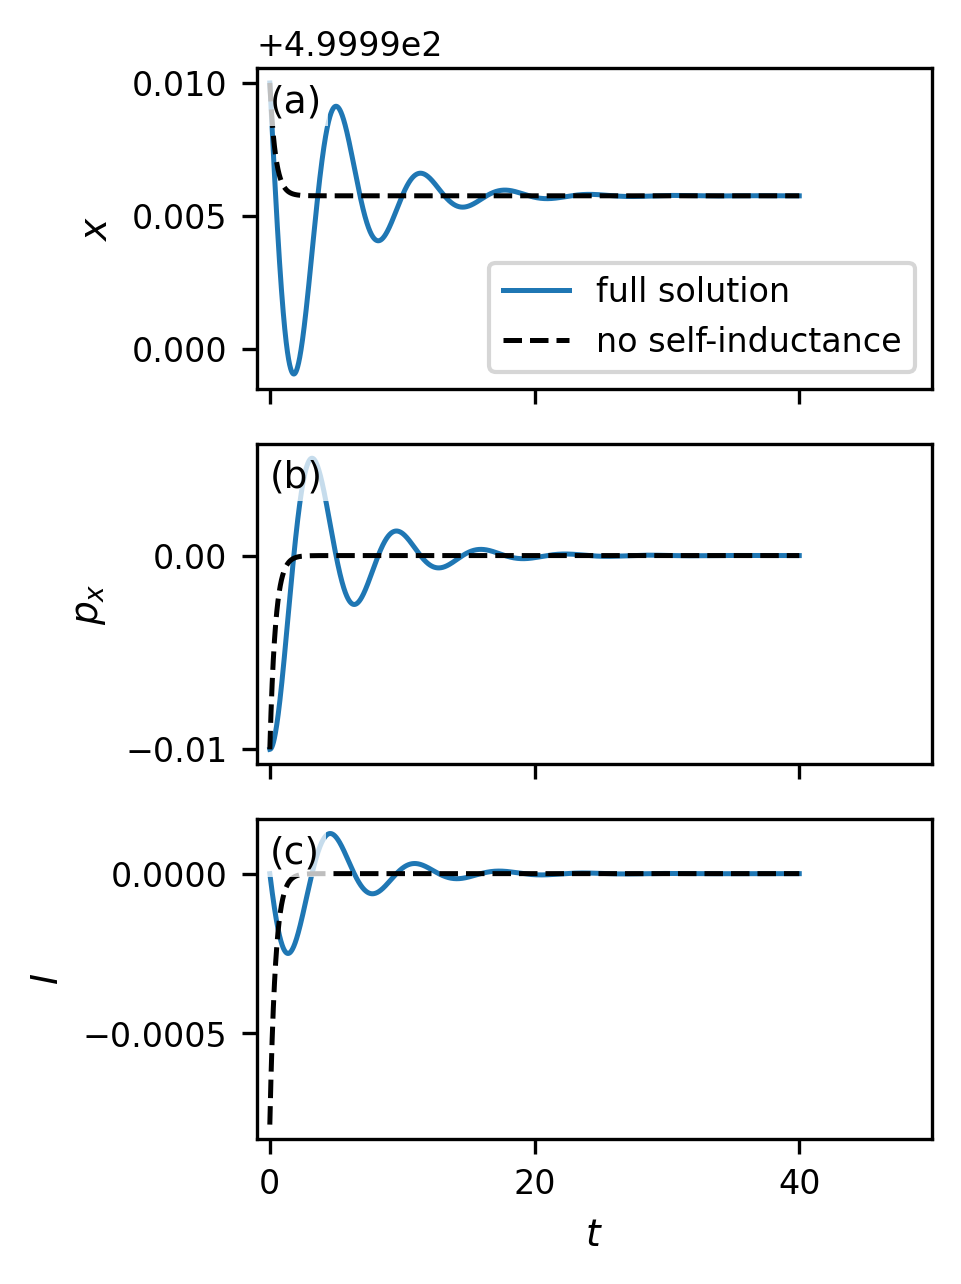

In [4]:
t0 = time.time()
B_large = 0.3
x_l, p_l, I_l, F_l, K_l, Eb_l, Q_l = dynamics.verlet_integrate(
    x0, p0, l, B_large, rho, dt, N_LARGE, N_PRINT_LARGE)
x_l, p_l, I_l = np.array(x_l), np.array(p_l), np.array(I_l)
t_l = N_PRINT_LARGE * dt * np.arange(len(x_l))
F_l = np.array(F_l[:len(t_l)])
Ftot_l = F_l[:, 0] + F_l[:, 1]
K_l, Eb_l, Q_l = np.array(K_l), np.array(Eb_l), np.array(Q_l)
print(f"ran {N_LARGE:,} steps in {time.time()-t0:.2f}s, {len(x_l)} points recorded")

x_model_l = models.x_pos0(t_l, x0, p0, B_large, rho, l)
p_model_l = models.p_pos0(t_l, p0, B_large, rho, l, x0)
I_model_l = models.I_pos0(t_l, p0, B_large, rho, l, x0)

fig = figures.plot_xpI(t_l, x_l, p_l, I_l, x_model_l, p_model_l, I_model_l, xlim=(-1, 50))
plt.show()


## Figure: energy vs $t$

Kinetic $K$, field $E_B$, dissipated heat $Q_{tot}$ (accumulated
magnitude) and their sum, which the paper states stays conserved to a
worst-case transient relative error of $\sim10^{-8}$. Reproduces the paper's energy
figure.

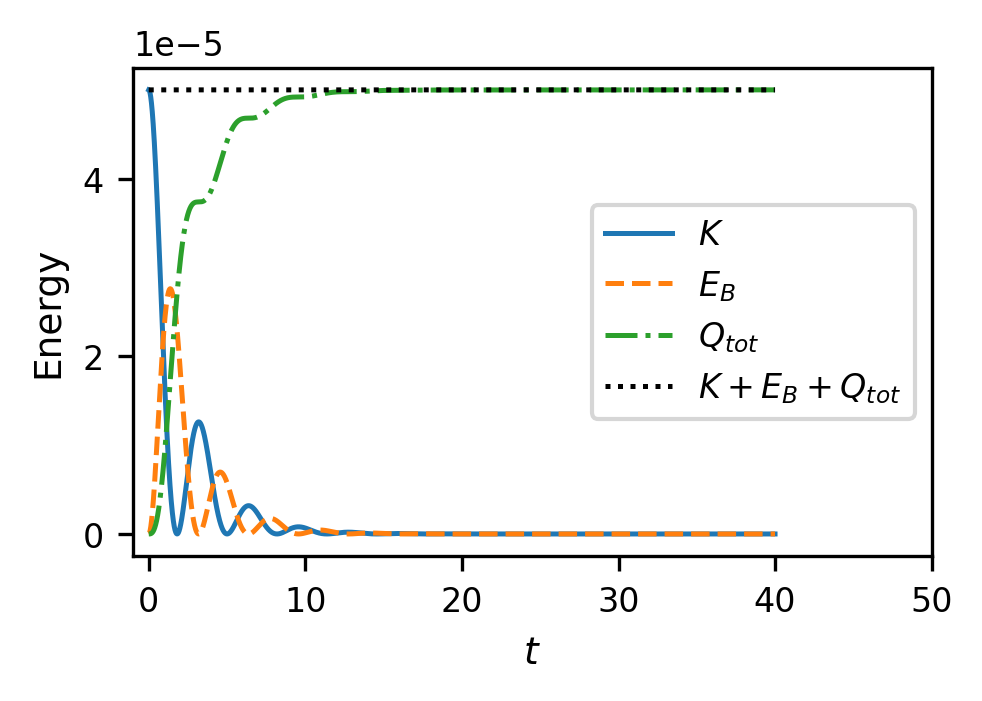

relative spread of K+E_B+Q_tot: 1.017e-08   (paper: ~1e-8)


In [5]:
E_total_l = K_l + Eb_l + Q_l
rel_spread = (E_total_l.max() - E_total_l.min()) / abs(E_total_l.mean())

fig = figures.plot_energy(t_l, K_l, Eb_l, Q_l, xlim=(-1, 50))
plt.show()

print(f"relative spread of K+E_B+Q_tot: {rel_spread:.3e}   (paper: ~1e-8)")


## Figure: force fit

Model (`fapp`): $F_x(t)\approx lB_0I_{mx}e^{-\alpha t}\cos(\omega_dt+\phi)$,
with $\alpha$ and $\omega_d$ fixed to their theoretical values (evaluated
at $x_0$); only $I_{mx}$ and $\phi$ are fit via
`scipy.optimize.curve_fit`. Paper: the fit achieves
$\mathrm{R}^2>0.996$ and RMSE$<10^{-4}$. Reproduces the paper's
force-fit figure.

R-squared: 0.9976, RMSE: 0.000083   (paper: R^2>0.996, RMSE<1e-4)
I_mx = 0.000326, phi (normalized) = -1.570580


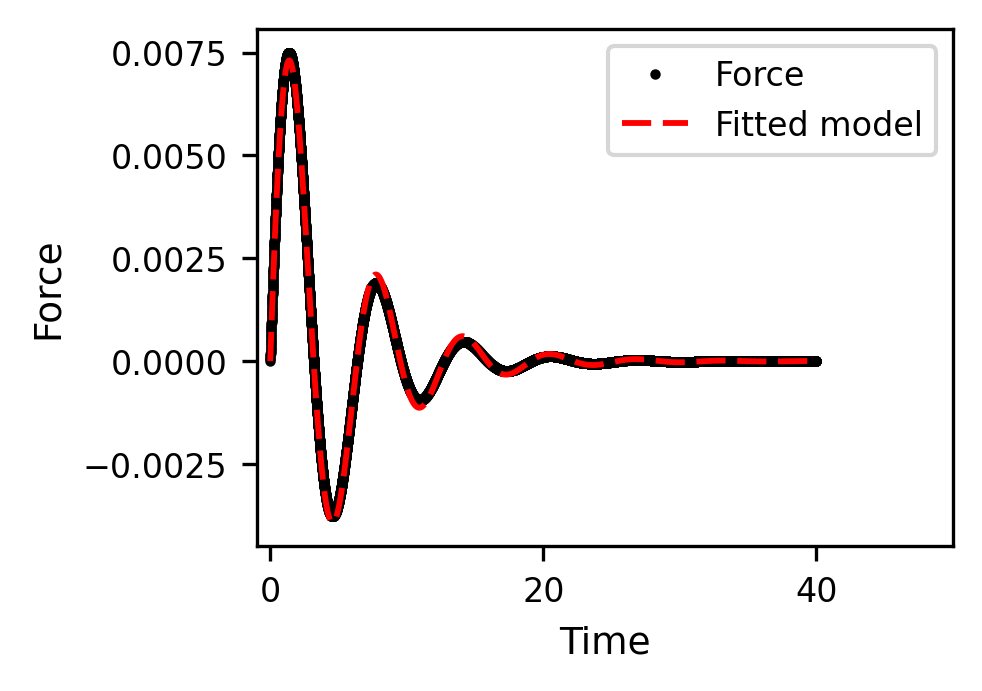

In [6]:
alpha = models.alpha_damp(l, rho)
omega_d = models.omega_predicted(l, x0, B_large, rho)

rsq, rmse, params = models.fit_to_function_fix_decay_freq([1e-4, 0], alpha, omega_d, t_l, Ftot_l)
params = dict((label, (val, err)) for label, val, err in params)
A_fit, phi_fit = params['A'][0], params['phi'][0]
A_norm, phi_norm = models.normalize_amplitude_phase(A_fit, phi_fit)
Imx_fit = A_norm / (l * B_large)

print(f"R-squared: {rsq:.4f}, RMSE: {rmse:.6f}   (paper: R^2>0.996, RMSE<1e-4)")
print(f"I_mx = {Imx_fit:.6f}, phi (normalized) = {phi_norm:.6f}")

Ffit = models.oscillating_exp_fix_decay_freq(t_l, A_fit, alpha, omega_d, phi_fit)
fig = figures.plot_force_fit(t_l, Ftot_l, Ffit, xlim=(-1, 50))
plt.show()


## Figure: self-inductance vs. Rosa/Grover

The self-inductance $L(x,l)$ derived in this work against the classical
closed-form expression of Rosa (1908)/Grover (2004), which assumes
$x,l\gg d$. Paper: visually indistinguishable, ratio within $0.5\%$ for
$x\geq100d$ and within $2\%$ in $L$ / $0.1\%$ in $dL/dx$ at $x=2d$,
$l/d=100$. Reproduces the paper's
self-inductance comparison figure.

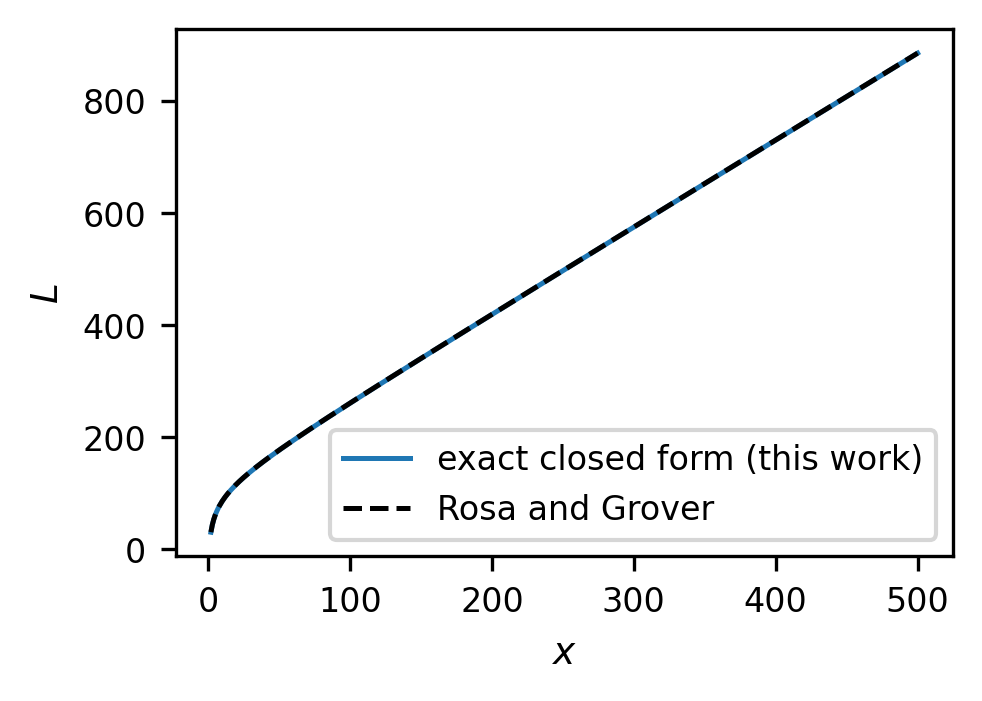

|1 - L_rosa/L| at x=100d:  0.049%   (paper: <0.5%)
|1 - L_rosa/L| at x=2d:    0.508%   (paper: <2%)
|1 - dLrosa/dL| at x=2d:   0.0770%   (paper: <0.1%)


In [7]:
def rosa_inductance(mu, l, x, d):
    r = np.sqrt(x**2 + l**2)
    return (mu/np.pi)*(x*np.log(np.abs(2*x/d)) + l*np.log(np.abs(2*l/d))
              - 0.75*(x+l) + 2*d - x*np.log(np.abs((r+x)/l)) + r - l
              - l*np.log(np.abs((r+l)/x)) + r - x)

def dL_rosa(mu, l, x, d):
    r = np.sqrt(x**2 + l**2)
    return (mu/np.pi)*(np.log(np.abs(2*x/d)) - np.log(np.abs((r+x)/l)) - 0.75
                        + x/r - l*x/(r*(r+l)) + l/x)

d = 1.0
x_arr = np.arange(2, 501)
L_eq = np.array([inductance.self_inductance(mu, d, l, xx) for xx in x_arr])
L_rosa_arr = rosa_inductance(mu, l, x_arr, d)
dL_eq = np.array([inductance.self_inductance_dx(mu, d, l, xx) for xx in x_arr])
dL_rosa_arr = dL_rosa(mu, l, x_arr, d)

fig = figures.plot_rosa_grover(x_arr, L_eq, L_rosa_arr)
plt.show()

ratio = L_rosa_arr / L_eq
i100 = np.argmin(np.abs(x_arr - 100))
i2 = np.argmin(np.abs(x_arr - 2))
print(f"|1 - L_rosa/L| at x=100d:  {abs(1-ratio[i100])*100:.3f}%   (paper: <0.5%)")
print(f"|1 - L_rosa/L| at x=2d:    {abs(1-ratio[i2])*100:.3f}%   (paper: <2%)")
print(f"|1 - dLrosa/dL| at x=2d:   {abs(1-dL_rosa_arr[i2]/dL_eq[i2])*100:.4f}%   (paper: <0.1%)")


## Figure: self-inductance vs. its asymptotic form

$L(x,l)$ compared with its $x\to\infty$ linear asymptote. Paper: error
already below $3\%$ at $x=100d$. Reproduces the paper's
self-inductance-vs-asymptote figure.

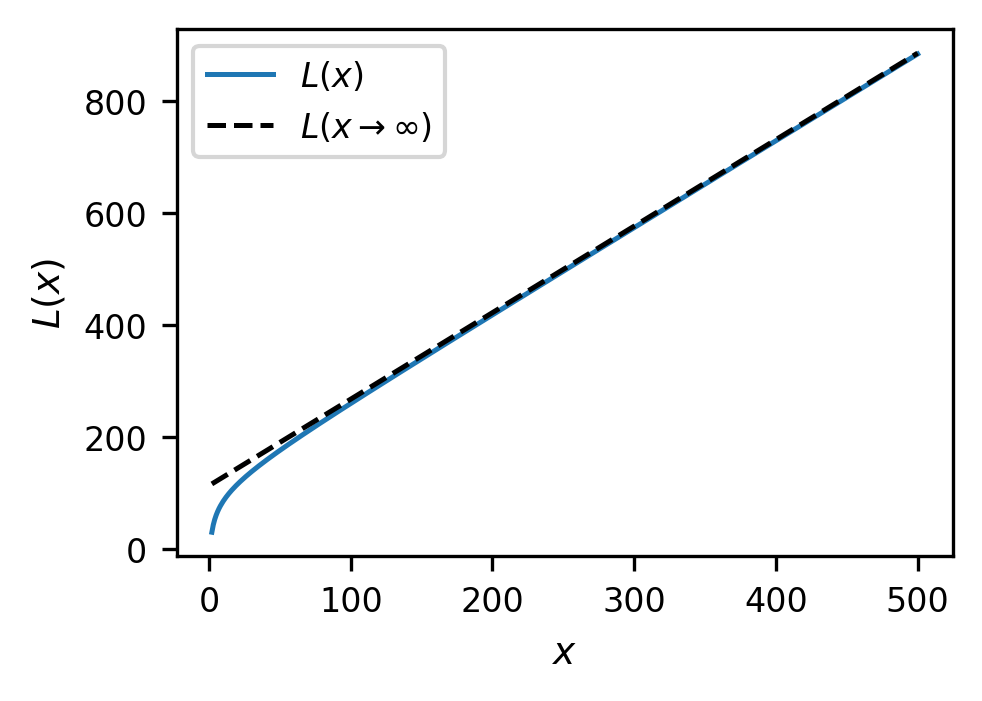

|L - L_asymp|/L at x=100d: 2.95%   (paper: <3%)


In [8]:
L_asymp_arr = np.array([inductance.self_inductance_asymp(mu, d, l, xx) for xx in x_arr])

fig = figures.plot_L_vs_asymptote(x_arr, L_eq, L_asymp_arr)
plt.show()

relerr_100d = abs(L_eq[i100] - L_asymp_arr[i100]) / L_eq[i100]
print(f"|L - L_asymp|/L at x=100d: {relerr_100d*100:.2f}%   (paper: <3%)")


## Figure: goodness of fit vs. $(\rho, B_0)$, and the crossover $B_{0,c}(\rho)$

$R^2$ of the two limiting-case models across a $(\rho, B_0)$ grid: the
damped-oscillator model (`fapp`) should be accurate for
$B_0>B_{0,c}(\rho)$ (under-damped), the no-self-inductance model
(`pos0`) for $B_0<B_{0,c}(\rho)$ (over-damped), with
$B_{0,c}(\rho)=\sqrt{M L(x_0)}\,\alpha(\rho)/l$ (eq. bcrit). Reproduces the paper's
goodness-of-fit figure.

**This is the expensive figure**: it runs the full simulation at every
grid point, for both models. The reduced default below uses a
$3\times3$ grid at a much shorter step count purely to demonstrate the
qualitative shape (the crossover boundary, and the two models scoring
well on opposite sides of it); set `FULL_RESOLUTION = True` above to
reproduce the paper's own $17\times17$, $10^6$-step grid (needs `numba`
to finish in a reasonable time -- see the runtime note at the top of
this notebook).

**Reduced-resolution note**: at only 20,000 steps (4 time units) per grid point, the no-self-inductance model's $R^2$ is noisy in the demo grid below (too short a window for its residuals to settle), even though the oscillator-model panel and the crossover location already come out clean. `FULL_RESOLUTION = True` uses the paper's own $10^6$-step runs, long enough for both panels to converge properly.

grid: 3x3, 20,000 steps/run, 18 total simulation runs


grid scan finished in 0.2s


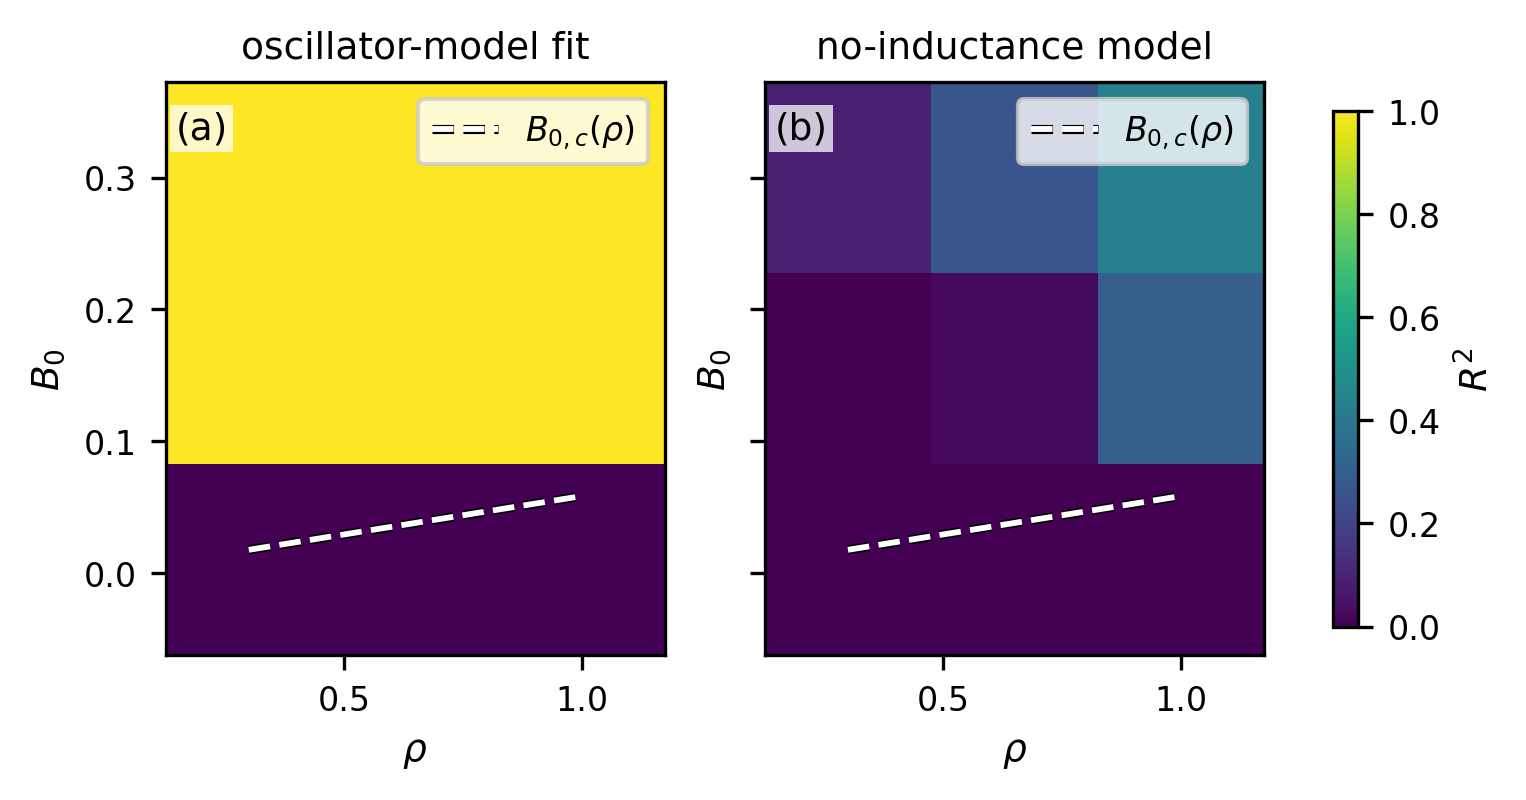

In [9]:
grid_n = 17 if FULL_RESOLUTION else 3
n_steps_scan = 1_000_000 if FULL_RESOLUTION else 20_000
n_print_scan = 20
rmin, rmax, bmin, bmax = 0.3, 1.0, 0.01, 0.3

rho_ax = np.linspace(rmin, rmax, grid_n)
B_ax = np.linspace(bmin, bmax, grid_n)
rho_grid, B_grid = np.meshgrid(rho_ax, B_ax)

print(f"grid: {grid_n}x{grid_n}, {n_steps_scan:,} steps/run, "
      f"{2*grid_n*grid_n} total simulation runs")
t0 = time.time()

Rsq_current = np.zeros_like(rho_grid)
Rsq_noselfL = np.zeros_like(rho_grid)
for i in range(grid_n):
    for j in range(grid_n):
        curr_rho, curr_B = rho_grid[i, j], B_grid[i, j]
        alpha_ij = models.alpha_damp(l, curr_rho)
        omega_ij = models.omega_predicted(l, x0, curr_B, curr_rho)

        xg, pg, Ig, Fg, Kg, Ebg, Qg = dynamics.verlet_integrate(
            x0, p0, l, curr_B, curr_rho, dt, n_steps_scan, n_print_scan)
        pg = np.array(pg)
        tg = n_print_scan * dt * np.arange(len(pg))
        Fg = np.array(Fg[:len(tg)])
        Ftot_g = Fg[:, 0] + Fg[:, 1]

        try:
            rsq_c, _, _ = models.fit_to_function_fix_decay_freq(
                [1e-4, 0], alpha_ij, omega_ij, tg, Ftot_g)
        except RuntimeError:
            rsq_c = np.nan
        Rsq_current[i, j] = rsq_c

        p_model = models.p_pos0(tg, p0, curr_B, curr_rho, l, x0)
        residuals = pg - p_model
        ss_res = np.sum(residuals**2)
        ss_tot = np.sum((pg - np.mean(pg))**2)
        Rsq_noselfL[i, j] = 1 - ss_res / ss_tot

print(f"grid scan finished in {time.time()-t0:.1f}s")

rho_line = np.linspace(rho_ax.min(), rho_ax.max(), 200)
B0c_line = np.array([models.B0_critical(l, x0, r) for r in rho_line])

fig = figures.plot_Rsq_heatmaps(rho_grid, B_grid, Rsq_current,
                                 rho_grid, B_grid, Rsq_noselfL,
                                 rho_line, B0c_line)
plt.show()


## Beyond the paper's four parameter sets

Everything above uses the paper's own $(B_0, \rho)$ values. The cell
below runs a single trajectory at parameters of your choosing --
change `B0_custom`, `rho_custom`, `x0_custom` or `p0_custom` and re-run.

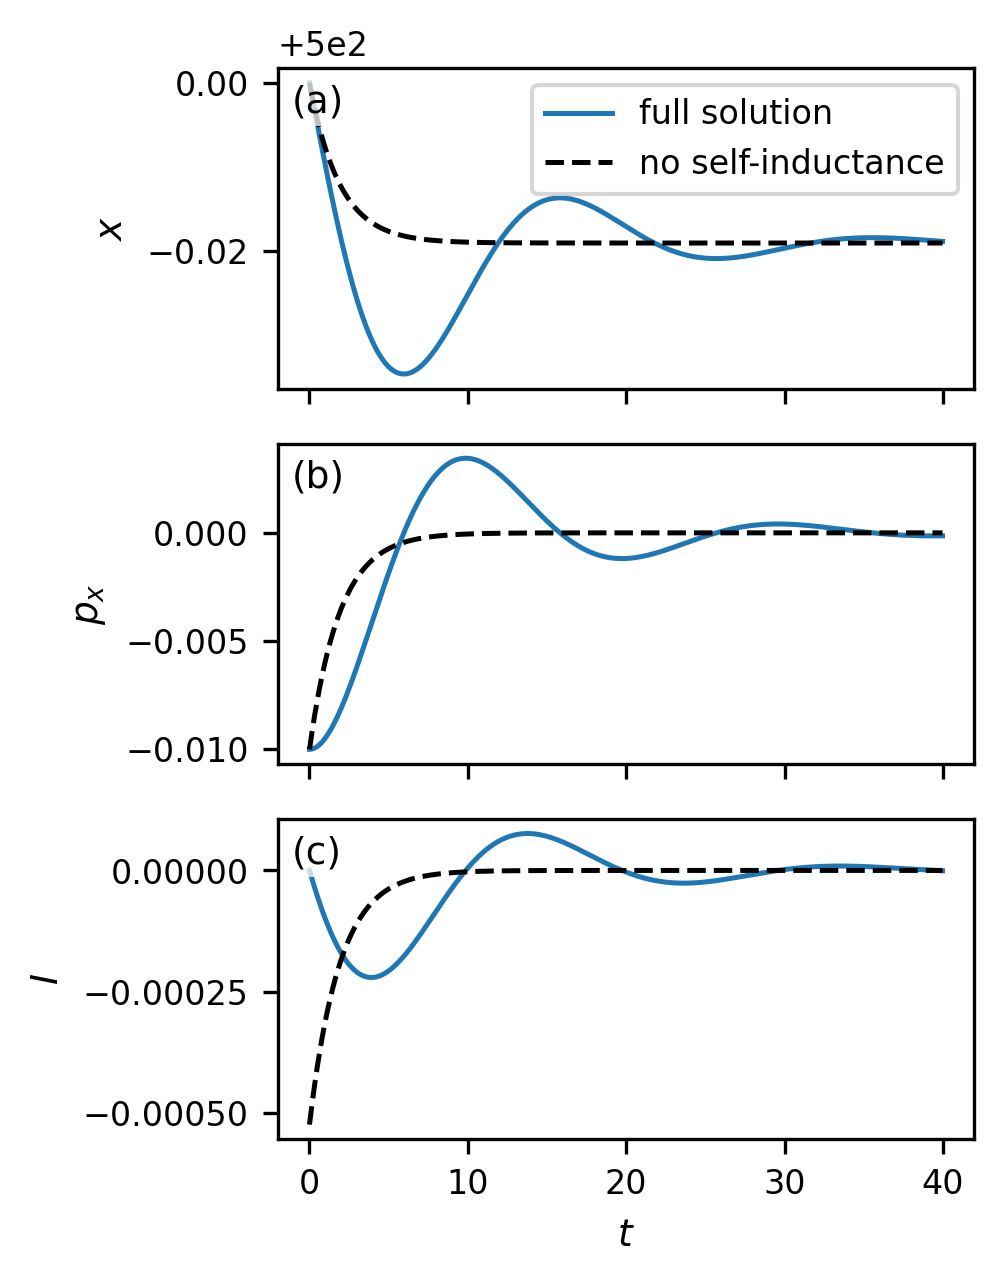

B0_c(rho=0.5) = 0.02913; B0=0.1 is in the under-damped regime


In [10]:
B0_custom = 0.1
rho_custom = 0.5
x0_custom = 500.0
p0_custom = -1.e-2
n_steps_custom = 200_000

xc, pc, Ic, Fc, Kc, Ebc, Qc = dynamics.verlet_integrate(
    x0_custom, p0_custom, l, B0_custom, rho_custom, dt, n_steps_custom, 100)
xc, pc, Ic = np.array(xc), np.array(pc), np.array(Ic)
tc = 100 * dt * np.arange(len(xc))

x_model_c = models.x_pos0(tc, x0_custom, p0_custom, B0_custom, rho_custom, l)
p_model_c = models.p_pos0(tc, p0_custom, B0_custom, rho_custom, l, x0_custom)
I_model_c = models.I_pos0(tc, p0_custom, B0_custom, rho_custom, l, x0_custom)

fig = figures.plot_xpI(tc, xc, pc, Ic, x_model_c, p_model_c, I_model_c)
plt.show()

B0c_custom = models.B0_critical(l, x0_custom, rho_custom)
regime = "under-damped" if B0_custom > B0c_custom else "over-damped"
print(f"B0_c(rho={rho_custom}) = {B0c_custom:.5f}; B0={B0_custom} is in the {regime} regime")
